# MM-IMDb Initial Dataset Analysis

This notebook is designed for the **Kaggle MM-IMDb distribution** containing:

- `metadata.npy`
- `multimodal_imdb.hdf5`

Dataset source: https://www.kaggle.com/datasets/johnarevalo/mmimdb/data

The aim is to verify dataset structure, modality availability, label quality, imbalance, missing/corrupted data, cross-modality alignment, and approximate Colab feasibility before beginning the full multimodal fusion project.

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Define the project folder

Recommended Google Drive structure:

```text
MyDrive/
└── MMIMDb_Project/
    ├── metadata.npy
    └── multimodal_imdb.hdf5
```

If you uploaded a ZIP instead, the next optional cell can extract it.

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/MMIMDb_Project")

print("Project directory:", PROJECT_DIR)
print("Folder exists:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    print("\nProject folder contents:")
    for item in sorted(PROJECT_DIR.iterdir()):
        print(" -", item.name)

Project directory: /content/drive/MyDrive/MMIMDb_Project
Folder exists: True

Project folder contents:
 - MMIMDb_initial_analysis_updated.ipynb
 - metadata.npy.zip
 - mmimdb_extracted
 - multimodal_imdb.hdf5.zip


## 3. Optional ZIP extraction

In [ ]:
import zipfile

zip_files = list(PROJECT_DIR.glob("*.zip"))

if zip_files:
    EXTRACT_DIR = PROJECT_DIR / "mmimdb_extracted"
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    for zip_path in zip_files:
        marker = EXTRACT_DIR / f".extracted_{zip_path.stem}"

        if marker.exists():
            print(f"Already extracted: {zip_path.name}")
            continue

        print(f"Extracting: {zip_path.name}")
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(EXTRACT_DIR)

        marker.touch()
        print(f"Extracted successfully: {zip_path.name}")
else:
    EXTRACT_DIR = PROJECT_DIR
    print("No ZIP archive found. Using the project folder directly.")

Extracting: metadata.npy.zip
Extracted successfully: metadata.npy.zip
Extracting: multimodal_imdb.hdf5.zip
Extracted successfully: multimodal_imdb.hdf5.zip


## 4. Locate the packaged MM-IMDb files

Unlike a raw JSON/JPEG layout, this Kaggle version stores metadata and multimodal data in two packaged binary files.

In [ ]:
import numpy as np
import h5py

metadata_candidates = list(EXTRACT_DIR.rglob("metadata.npy"))
hdf5_candidates = list(EXTRACT_DIR.rglob("multimodal_imdb.hdf5"))

print("metadata.npy files found:", len(metadata_candidates))
print("multimodal_imdb.hdf5 files found:", len(hdf5_candidates))

if not metadata_candidates:
    raise FileNotFoundError("metadata.npy was not found.")

if not hdf5_candidates:
    raise FileNotFoundError("multimodal_imdb.hdf5 was not found.")

metadata_path = metadata_candidates[0]
hdf5_path = hdf5_candidates[0]

print("\nMetadata path:", metadata_path)
print("HDF5 path:", hdf5_path)
print("Metadata size (MB):", round(metadata_path.stat().st_size / 1024**2, 2))
print("HDF5 size (GB):", round(hdf5_path.stat().st_size / 1024**3, 2))

metadata.npy files found: 1
multimodal_imdb.hdf5 files found: 1

Metadata path: /content/drive/MyDrive/MMIMDb_Project/mmimdb_extracted/metadata.npy
HDF5 path: /content/drive/MyDrive/MMIMDb_Project/mmimdb_extracted/multimodal_imdb.hdf5
Metadata size (MB): 61.48
HDF5 size (GB): 14.57


## 5. Inspect `metadata.npy`

This section first discovers the metadata structure without assuming its exact layout.

In [ ]:
metadata = np.load(metadata_path, allow_pickle=True)

print("Loaded object type:", type(metadata))
print("Shape:", getattr(metadata, "shape", None))
print("Dtype:", getattr(metadata, "dtype", None))

if isinstance(metadata, np.ndarray) and metadata.shape == ():
    metadata_obj = metadata.item()
else:
    metadata_obj = metadata

print("Converted object type:", type(metadata_obj))

Loaded object type: <class 'numpy.ndarray'>
Shape: ()
Dtype: object
Converted object type: <class 'dict'>


In [ ]:
def preview_object(obj, max_items=3):
    if isinstance(obj, dict):
        print("Dictionary keys:", list(obj.keys())[:20])
        for i, (k, v) in enumerate(obj.items()):
            if i >= max_items:
                break
            print(f"\nKey: {k}")
            print("Value type:", type(v))
            text = repr(v)
            print(text[:1200] + ("..." if len(text) > 1200 else ""))
    elif isinstance(obj, (list, tuple, np.ndarray)):
        print("Number of entries:", len(obj))
        for i in range(min(max_items, len(obj))):
            print(f"\nEntry {i}:")
            text = repr(obj[i])
            print(text[:1500] + ("..." if len(text) > 1500 else ""))
    else:
        text = repr(obj)
        print(text[:3000] + ("..." if len(text) > 3000 else ""))

preview_object(metadata_obj)

Dictionary keys: ['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

Key: lookup
Value type: <class 'numpy.ndarray'>
array([[ 8.00781250e-02,  1.04980469e-01,  4.98046875e-02, ...,
         3.66210938e-03,  4.76074219e-02, -6.88476562e-02],
       [ 7.03125000e-02,  8.69140625e-02,  8.78906250e-02, ...,
        -4.76074219e-02,  1.44653320e-02, -6.25000000e-02],
       [ 7.04956055e-03, -7.32421875e-02,  1.71875000e-01, ...,
         1.12304688e-02,  1.64062500e-01,  1.06933594e-01],
       ...,
       [ 7.51953125e-02,  5.54687500e-01, -1.60156250e-01, ...,
        -5.31250000e-01,  2.92968750e-01,  2.08007812e-01],
       [ 2.70996094e-02, -2.80380249e-04,  1.27929688e-01, ...,
         9.17968750e-02, -2.18505859e-02,  2.15820312e-01],
       [ 1.27929688e-01, -1.04003906e-01,  1.43554688e-01, ...,
        -5.61523438e-02,  1.02050781e-01, -1.06933594e-01]],
      shape=(41611, 300), dtype=float32)

Key: vocab_size
Value type: <class 'int'>
69980

Key: word_to_ix
Value type: <clas

## 6. Inspect the HDF5 structure

The recursive listing below prints every HDF5 dataset with its shape and datatype.

In [ ]:
def describe_hdf5(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(f"DATASET: {name} | shape={obj.shape} | dtype={obj.dtype}")
    elif isinstance(obj, h5py.Group):
        print(f"GROUP:   {name}")

with h5py.File(hdf5_path, "r") as f:
    print("Top-level keys:", list(f.keys()))
    print("\nFull HDF5 structure:")
    f.visititems(describe_hdf5)

Top-level keys: ['features', 'genres', 'images', 'imdb_ids', 'sequences', 'three_grams', 'vgg_features', 'word_grams']

Full HDF5 structure:
DATASET: features | shape=(25959, 300) | dtype=float32
DATASET: genres | shape=(25959, 23) | dtype=int32
DATASET: images | shape=(25959, 3, 256, 160) | dtype=int32
DATASET: imdb_ids | shape=(25959,) | dtype=|S7
DATASET: sequences | shape=(25959,) | dtype=object
DATASET: three_grams | shape=(25959, 9946) | dtype=float32
DATASET: vgg_features | shape=(25959, 4096) | dtype=float32
DATASET: word_grams | shape=(25959, 13253) | dtype=float32


## 7. Build a compact HDF5 summary and identify likely modalities

In [ ]:
hdf5_summary = []

with h5py.File(hdf5_path, "r") as f:
    def collect(name, obj):
        if isinstance(obj, h5py.Dataset):
            hdf5_summary.append({
                "name": name,
                "shape": obj.shape,
                "dtype": str(obj.dtype),
                "ndim": obj.ndim,
            })
    f.visititems(collect)

print("Datasets discovered:", len(hdf5_summary))

for info in hdf5_summary:
    print(
        f"{info['name']:<40} "
        f"shape={str(info['shape']):<24} "
        f"dtype={info['dtype']}"
    )

Datasets discovered: 8
features                                 shape=(25959, 300)             dtype=float32
genres                                   shape=(25959, 23)              dtype=int32
images                                   shape=(25959, 3, 256, 160)     dtype=int32
imdb_ids                                 shape=(25959,)                 dtype=|S7
sequences                                shape=(25959,)                 dtype=object
three_grams                              shape=(25959, 9946)            dtype=float32
vgg_features                             shape=(25959, 4096)            dtype=float32
word_grams                               shape=(25959, 13253)           dtype=float32


In [ ]:
image_candidates = []
label_candidates = []
text_candidates = []

for info in hdf5_summary:
    name = info["name"].lower()
    shape = info["shape"]

    if any(k in name for k in ["image", "img", "poster"]) or len(shape) >= 3:
        image_candidates.append(info)

    if any(k in name for k in ["label", "genre", "target"]) or (
        len(shape) == 2 and shape[-1] <= 100
    ):
        label_candidates.append(info)

    if any(k in name for k in ["text", "plot", "summary", "description", "token"]):
        text_candidates.append(info)

print("Likely image datasets:")
for x in image_candidates:
    print(" -", x)

print("\nLikely label datasets:")
for x in label_candidates:
    print(" -", x)

print("\nLikely text datasets:")
for x in text_candidates:
    print(" -", x)

Likely image datasets:
 - {'name': 'images', 'shape': (25959, 3, 256, 160), 'dtype': 'int32', 'ndim': 4}

Likely label datasets:
 - {'name': 'genres', 'shape': (25959, 23), 'dtype': 'int32', 'ndim': 2}

Likely text datasets:


## 8. Convert metadata into a Pandas DataFrame where possible

In [ ]:
import pandas as pd

def metadata_to_dataframe(obj):
    if isinstance(obj, pd.DataFrame):
        return obj.copy()

    if isinstance(obj, dict):
        # dictionary keyed by movie/sample ID
        if obj and all(isinstance(v, dict) for v in obj.values()):
            df = pd.DataFrame.from_dict(obj, orient="index")
            df.index.name = "sample_id"
            return df.reset_index()

        # dictionary of equally sized column arrays
        try:
            return pd.DataFrame(obj)
        except Exception:
            return pd.DataFrame(
                [{"key": k, "value": v} for k, v in obj.items()]
            )

    if isinstance(obj, np.ndarray):
        if obj.dtype.names:
            return pd.DataFrame.from_records(obj)
        if obj.dtype == object:
            return metadata_to_dataframe(obj.tolist())
        return pd.DataFrame(obj)

    if isinstance(obj, (list, tuple)):
        if len(obj) == 0:
            return pd.DataFrame()
        if all(isinstance(x, dict) for x in obj):
            return pd.DataFrame(obj)
        return pd.DataFrame({"value": obj})

    return pd.DataFrame({"value": [obj]})

metadata_df = metadata_to_dataframe(metadata_obj)

print("Metadata DataFrame shape:", metadata_df.shape)
print("\nColumns:")
print(metadata_df.columns.tolist())

display(metadata_df.head())

Metadata DataFrame shape: (4, 2)

Columns:
['key', 'value']


,key,value
0,lookup,"[[0.080078125, 0.10498047, 0.049804688, 0.0534..."
1,vocab_size,69980
2,word_to_ix,"{'complicating': 9988, 'shops': 10358, 'shiela..."
3,ix_to_word,"{0: '_UNK_', 1: ',', 2: 'the', 3: '.', 4: 'a',..."


## 9. Basic metadata quality assessment

In [ ]:
import numpy as np
import pandas as pd

print("Metadata records:", len(metadata_df))

# creating a copy with unhashable items converted to strings
temp_df = metadata_df.copy()
for col in temp_df.columns:
    if temp_df[col].apply(lambda x: isinstance(x, (list, np.ndarray, dict))).any():
        temp_df[col] = temp_df[col].astype(str)

print("Duplicate rows:", temp_df.duplicated().sum())

quality_summary = pd.DataFrame({
    "column": metadata_df.columns,
    "dtype": [str(metadata_df[c].dtype) for c in metadata_df.columns],
    "missing": [metadata_df[c].isna().sum() for c in metadata_df.columns],
    "missing_percent": [
        metadata_df[c].isna().mean() * 100 for c in metadata_df.columns
    ],
    "unique_values": [
        temp_df[c].nunique(dropna=True) for c in metadata_df.columns
    ],
})

display(
    quality_summary.sort_values(
        "missing_percent",
        ascending=False
    ).reset_index(drop=True)
)

Metadata records: 4
Duplicate rows: 0


,column,dtype,missing,missing_percent,unique_values
0,key,object,0,0.0,4
1,value,object,0,0.0,4


In [ ]:
import numpy as np
import pandas as pd

print("Metadata records:", len(metadata_df))

# Create a copy with unhashable items converted to strings
temp_df = metadata_df.copy()
for col in temp_df.columns:
    if temp_df[col].apply(lambda x: isinstance(x, (list, np.ndarray, dict))).any():
        temp_df[col] = temp_df[col].astype(str)

print("Duplicate rows:", temp_df.duplicated().sum())

quality_summary = pd.DataFrame({
    "column": metadata_df.columns,
    "dtype": [str(metadata_df[c].dtype) for c in metadata_df.columns],
    "missing": [metadata_df[c].isna().sum() for c in metadata_df.columns],
    "missing_percent": [
        metadata_df[c].isna().mean() * 100 for c in metadata_df.columns
    ],
    "unique_values": [
        temp_df[c].nunique(dropna=True) for c in metadata_df.columns
    ],
})

display(
    quality_summary.sort_values(
        "missing_percent",
        ascending=False
    ).reset_index(drop=True)
)

Metadata records: 4
Duplicate rows: 0


,column,dtype,missing,missing_percent,unique_values
0,key,object,0,0.0,4
1,value,object,0,0.0,4


## 10. Detect likely title, plot-summary, and genre fields

In [ ]:
column_lookup = {str(c).lower(): c for c in metadata_df.columns}

def find_first_column(keywords):
    for lower_name, original_name in column_lookup.items():
        if any(k in lower_name for k in keywords):
            return original_name
    return None

title_col = find_first_column(["title", "movie_name", "name"])
plot_col = find_first_column(["plot", "summary", "description", "synopsis", "story"])
genre_col = find_first_column(["genre", "genres", "label", "labels"])

print("Likely title column:", title_col)
print("Likely plot column:", plot_col)
print("Likely genre column:", genre_col)

Likely title column: None
Likely plot column: None
Likely genre column: None


## 11. Plot-summary quality analysis

If a text field is detected, this section examines empty summaries and text-length distribution.

In [ ]:
import matplotlib.pyplot as plt

def normalise_text(value):
    if value is None:
        return ""
    if isinstance(value, float) and np.isnan(value):
        return ""
    if isinstance(value, (list, tuple, np.ndarray)):
        return " ".join(str(x) for x in value)
    return str(value)

if plot_col is not None:
    plot_text = metadata_df[plot_col].apply(normalise_text)
    word_counts = plot_text.str.split().str.len()

    print("Plot summaries analysed:", len(plot_text))
    print("Empty plot summaries:", (plot_text.str.strip() == "").sum())
    print("Mean words:", round(word_counts.mean(), 1))
    print("Median words:", round(word_counts.median(), 1))
    print("Minimum words:", int(word_counts.min()))
    print("Maximum words:", int(word_counts.max()))

    upper = word_counts.quantile(0.99)

    plt.figure(figsize=(9, 5))
    plt.hist(word_counts.clip(upper=upper), bins=40)
    plt.title("Figure 1. Distribution of Plot-Summary Lengths")
    plt.xlabel("Number of Words")
    plt.ylabel("Number of Movies")
    plt.tight_layout()
    plt.show()

    print("\nExample plot summaries:")
    for text in plot_text[plot_text.str.strip() != ""].head(3):
        print("\n---")
        print(text[:1000])
else:
    print(
        "No plot-summary field was automatically detected. "
        "Use the metadata preview above to identify it manually if necessary."
    )

No plot-summary field was automatically detected. Use the metadata preview above to identify it manually if necessary.


## 12. Multi-label genre analysis

In [ ]:
from collections import Counter
import ast

def parse_genres(value):
    if value is None:
        return []

    if isinstance(value, float) and np.isnan(value):
        return []

    if isinstance(value, (list, tuple, set, np.ndarray)):
        return [str(x).strip() for x in value if str(x).strip()]

    text = str(value).strip()

    if not text:
        return []

    if text.startswith("[") and text.endswith("]"):
        try:
            parsed = ast.literal_eval(text)
            if isinstance(parsed, (list, tuple, set)):
                return [str(x).strip() for x in parsed if str(x).strip()]
        except Exception:
            pass

    for sep in ["|", ",", ";"]:
        if sep in text:
            return [x.strip() for x in text.split(sep) if x.strip()]

    return [text]

if genre_col is not None:
    parsed_genres = metadata_df[genre_col].apply(parse_genres)

    genre_counter = Counter(
        genre
        for genres in parsed_genres
        for genre in genres
    )

    genre_counts_df = (
        pd.DataFrame(
            genre_counter.items(),
            columns=["genre", "count"]
        )
        .sort_values("count", ascending=False)
        .reset_index(drop=True)
    )

    labels_per_movie = parsed_genres.apply(len)

    print("Unique genres:", len(genre_counts_df))
    print("Movies with no genre:", (labels_per_movie == 0).sum())
    print("Mean genres per movie:", round(labels_per_movie.mean(), 2))
    print("Median genres per movie:", round(labels_per_movie.median(), 2))
    print("Maximum genres on one movie:", int(labels_per_movie.max()))

    display(genre_counts_df)

    plt.figure(figsize=(11, 6))
    plt.bar(genre_counts_df["genre"], genre_counts_df["count"])
    plt.title("Figure 2. MM-IMDb Genre Frequency")
    plt.xlabel("Genre")
    plt.ylabel("Number of Movies")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    labels_per_movie.value_counts().sort_index().plot(kind="bar")
    plt.title("Figure 3. Number of Genre Labels per Movie")
    plt.xlabel("Number of Genres")
    plt.ylabel("Number of Movies")
    plt.tight_layout()
    plt.show()
else:
    print(
        "No genre field was detected in metadata. "
        "The target matrix may instead be stored inside the HDF5 file."
    )

No genre field was detected in metadata. The target matrix may instead be stored inside the HDF5 file.


## 13. Select and preview likely image data

In [ ]:
def choose_image_dataset(candidates):
    for item in candidates:
        name = item["name"].lower()
        if any(k in name for k in ["image", "poster", "img"]):
            return item["name"]

    for item in candidates:
        if len(item["shape"]) >= 3:
            return item["name"]

    return None

image_dataset_name = choose_image_dataset(image_candidates)

print("Selected image dataset:", image_dataset_name)

Selected image dataset: images


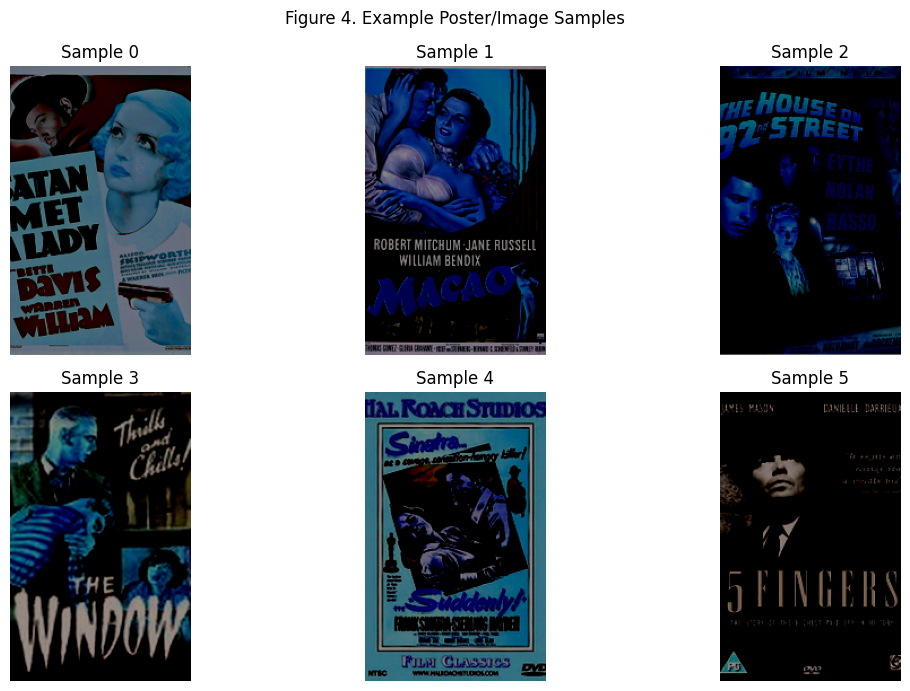

In [ ]:
import math

if image_dataset_name is not None:
    with h5py.File(hdf5_path, "r") as f:
        ds = f[image_dataset_name]

        n_show = min(6, ds.shape[0])
        rows = 2
        cols = math.ceil(n_show / rows)

        fig, axes = plt.subplots(rows, cols, figsize=(12, 7))
        axes = np.array(axes).reshape(-1)

        for i in range(n_show):
            img = np.asarray(ds[i])

            if (
                img.ndim == 3
                and img.shape[0] in (1, 3, 4)
                and img.shape[-1] not in (1, 3, 4)
            ):
                img = np.transpose(img, (1, 2, 0))

            img = np.squeeze(img)

            axes[i].imshow(
                img,
                cmap="gray" if img.ndim == 2 else None
            )
            axes[i].set_title(f"Sample {i}")
            axes[i].axis("off")

        for j in range(n_show, len(axes)):
            axes[j].axis("off")

        fig.suptitle("Figure 4. Example Poster/Image Samples")
        plt.tight_layout()
        plt.show()
else:
    print(
        "No image-like HDF5 dataset was detected automatically. "
        "Use the HDF5 structure above to assign image_dataset_name manually."
    )

## 14. Sampled image-quality assessment

Images sampled: 1000
Non-finite arrays: 0
Near-constant images (std < 1e-6): 0


,index,shape,finite,mean,std,min,max
0,0,"(3, 256, 160)",True,44.183372,73.987656,-123.0,138.0
1,25,"(3, 256, 160)",True,13.766471,92.065063,-123.0,151.0
2,51,"(3, 256, 160)",True,-67.941658,58.474636,-123.0,144.0
3,77,"(3, 256, 160)",True,25.118782,62.665760,-116.0,140.0
4,103,"(3, 256, 160)",True,-62.793068,57.495495,-123.0,151.0


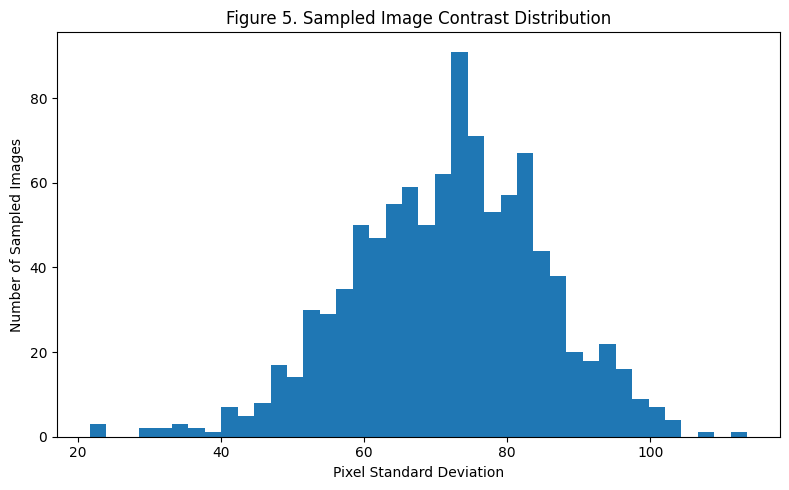

In [ ]:
if image_dataset_name is not None:
    with h5py.File(hdf5_path, "r") as f:
        ds = f[image_dataset_name]

        sample_n = min(1000, ds.shape[0])
        sample_indices = np.linspace(
            0,
            ds.shape[0] - 1,
            sample_n,
            dtype=int
        )

        image_records = []

        for idx in sample_indices:
            arr = np.asarray(ds[idx])
            arr_float = arr.astype(np.float32, copy=False)

            image_records.append({
                "index": int(idx),
                "shape": tuple(arr.shape),
                "finite": bool(np.isfinite(arr_float).all()),
                "mean": float(np.nanmean(arr_float)),
                "std": float(np.nanstd(arr_float)),
                "min": float(np.nanmin(arr_float)),
                "max": float(np.nanmax(arr_float)),
            })

    image_quality_df = pd.DataFrame(image_records)

    print("Images sampled:", len(image_quality_df))
    print("Non-finite arrays:", (~image_quality_df["finite"]).sum())
    print(
        "Near-constant images (std < 1e-6):",
        (image_quality_df["std"] < 1e-6).sum()
    )

    display(image_quality_df.head())

    plt.figure(figsize=(8, 5))
    plt.hist(image_quality_df["std"], bins=40)
    plt.title("Figure 5. Sampled Image Contrast Distribution")
    plt.xlabel("Pixel Standard Deviation")
    plt.ylabel("Number of Sampled Images")
    plt.tight_layout()
    plt.show()
else:
    print("Image-quality assessment skipped.")

## 15. Cross-modality sample-count check

This checks whether the first dimension of likely HDF5 datasets is compatible with the metadata sample count.

In [ ]:
counts = {
    "metadata_records": len(metadata_df)
}

for info in hdf5_summary:
    if len(info["shape"]) >= 1:
        counts[f"hdf5::{info['name']}"] = info["shape"][0]

counts_df = pd.DataFrame(
    counts.items(),
    columns=["source", "sample_count"]
)

display(counts_df)

main_count = len(metadata_df)

matching = counts_df[
    counts_df["sample_count"] == main_count
]

print(
    f"\nHDF5 datasets with the same first-dimension count as metadata: "
    f"{len(matching) - 1 if len(matching) > 0 else 0}"
)

print(
    "Note: different counts do not automatically indicate an error because "
    "some HDF5 objects can be auxiliary lookup tables."
)

,source,sample_count
0,metadata_records,4
1,hdf5::features,25959
2,hdf5::genres,25959
3,hdf5::images,25959
4,hdf5::imdb_ids,25959
5,hdf5::sequences,25959
6,hdf5::three_grams,25959
7,hdf5::vgg_features,25959
8,hdf5::word_grams,25959



HDF5 datasets with the same first-dimension count as metadata: 0
Note: different counts do not automatically indicate an error because some HDF5 objects can be auxiliary lookup tables.


## 16. Class-imbalance summary

In [ ]:
if genre_col is not None and "genre_counts_df" in globals() and len(genre_counts_df) > 0:
    most_common = genre_counts_df.iloc[0]
    least_common = genre_counts_df.iloc[-1]

    ratio = (
        float(most_common["count"]) / float(least_common["count"])
        if least_common["count"] > 0
        else np.inf
    )

    print("Most frequent genre:", most_common.to_dict())
    print("Least frequent genre:", least_common.to_dict())
    print("Max/min class-frequency ratio:", round(ratio, 2))
else:
    print("Automatic genre imbalance summary unavailable.")

Automatic genre imbalance summary unavailable.


## 17. Approximate Colab feasibility

The HDF5 file is large, so the final project should avoid repeatedly loading the entire dataset into RAM.


In [ ]:
import os
import psutil

process = psutil.Process(os.getpid())

print(
    "Current Python process RAM usage (GB):",
    round(process.memory_info().rss / 1024**3, 3)
)

print(
    "HDF5 file size (GB):",
    round(hdf5_path.stat().st_size / 1024**3, 2)
)

print(
    "Metadata file size (MB):",
    round(metadata_path.stat().st_size / 1024**2, 2)
)

Current Python process RAM usage (GB): 0.261
HDF5 file size (GB): 14.57
Metadata file size (MB): 61.48
